<a href="https://colab.research.google.com/github/maliaheupel/walmart/blob/main/notebooks/scratch/2026_10_30_%E2%80%94_Midterm_Progress_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [1]:
# quick cleaning so variables and cleaned versions can be used here
import pandas as pd
import matplotlib.pyplot as plt

# Load transaction data
transactions = pd.read_csv("walmart_transactions.csv")

# Cleaning function
def clean_transactions(df):
    out = df.drop_duplicates().copy()

    # Clean unit prices
    out['unit_price'] = (
        out['unit_price']
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.strip()
        .astype(float)
    )

    # Parse timestamps
    out['timestamp'] = pd.to_datetime(
        out['timestamp'],
        errors='coerce',
        format='mixed'
    )

    # Standardize store IDs
    out['store_id'] = (
        out['store_id']
        .str.upper()
        .str.strip()
        .str.replace(r'[^A-Z0-9]', '', regex=True)
        .apply(lambda s: f'{s[:2]}-{s[2:]}')
    )

    # Standardize category formatting
    out['category'] = (
        out['category']
        .str.strip()
        .str.title()
    )
    # Consolidate equivalent category names
    category_map = {
      'Alcohol': 'Alcoholic Beverages',
      'Baby': 'Baby Products',
      'Breakfast': 'Breakfast Foods',
      'Emergency': 'Emergency Supplies',
      'Games & Entertainment': 'Entertainment',
      'Grocery': 'Groceries',
      'Health': 'Health & Wellness',
      'Household': 'Household Essentials'
  }

    out['category'] = out['category'].replace(category_map)

    return out


cleaned = clean_transactions(transactions)

# Keep usable rows for gross demand analysis
q1 = cleaned[
    cleaned['timestamp'].notna() &
    (cleaned['quantity'] > 0)
].copy()

q1['date'] = q1['timestamp'].dt.normalize()

# Find the five categories with the most total units
top_categories = (
    q1.groupby('category')['quantity']
    .sum()
    .nlargest(5)
    .index
)

# Daily units sold for those categories
daily = (
    q1[q1['category'].isin(top_categories)]
    .groupby(['date', 'category'])['quantity']
    .sum()
    .unstack(fill_value=0)
)

landfall = pd.Timestamp('2024-09-26')

In [2]:
# TODO 1:
# Calculate the pre-storm baseline for each category
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()

# Divide each day's sales by that category's baseline
indexed = daily / baseline

# Show the highest surge multiple for each category
print("Peak multiple of baseline:")
print(indexed.max().round(1).sort_values(ascending=False))

# Surge window average
surge_window = daily[(daily.index >= landfall-pd.Timedelta(days=3)) & (daily.index < landfall)].mean()
surge_multiple = surge_window/baseline

Peak multiple of baseline:
category
Breakfast Foods         5.6
Emergency Supplies      3.4
Entertainment           2.9
Household Essentials    2.7
Groceries               2.1
dtype: float64


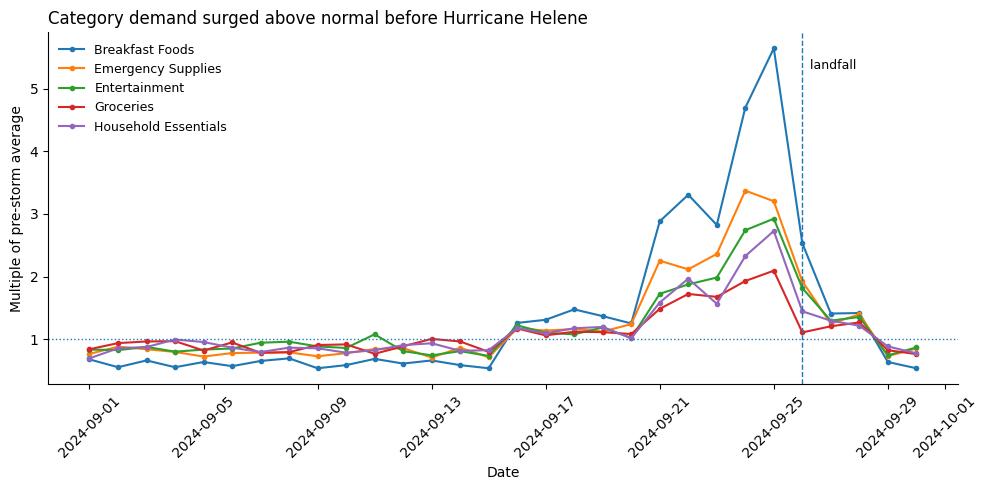

In [3]:
# TODO 2
# Plot each category as a multiple of normal demand
fig, ax = plt.subplots(figsize=(10, 5))

for col in indexed.columns:
    ax.plot(
        indexed.index,
        indexed[col],
        marker='o',
        markersize=3,
        label=col
    )

# Normal demand = 1.0
ax.axhline(
    1.0,
    linestyle=':',
    linewidth=1
)

# Hurricane Helene landfall
ax.axvline(
    landfall,
    linestyle='--',
    linewidth=1
)

ax.annotate(
    '  landfall',
    xy=(landfall, ax.get_ylim()[1] * 0.9),
    fontsize=9
)

ax.set_title(
    'Category demand surged above normal before Hurricane Helene',
    loc='left',
    fontsize=12
)

ax.set_xlabel('Date')
ax.set_ylabel('Multiple of pre-storm average')

ax.legend(frameon=False, fontsize=9)

for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** During the 3-day pre-storm window (September 23-25), daily product demand spiked well above the pre-Sept 23 baseline for all five categories, led by Breakfast Foods at 3.4x normal volume followed by Emergency Supplies (2.4x), Entertainment (2.3x), Household Essentials (2.2x), and Groceries (1.8x).

### Q2 — SKU consolidation



**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

catalog shape:


(45, 7)


Distinct SKUs:
45

Product names:


,sku,product_name
0,PT-12,pop-tarts strawberry
1,SKU#459812,Strawberry Pop-Tart
2,POPTART-STRAW,Pop-Tarts Strawberry
3,PT_STRAWBERRY,pop-tarts strawberry
4,WTR-24,BOTTLED WATER 24PK
5,WATER24PK,Bottled Water 24-Pack
6,WTR_24PK,Water - 24 Pack
7,BATT-100,BATTERIES AA 4PK
8,BAT-AA4,AA Batteries 4-Pack
9,BATT_AA_4PK,AA Batteries 4-Pack


,name_key,sku,product_name
12,24 beer light pack,BEER-24,Light Beer (24-pack)
13,24 beer light pack,LTBEER24,Light Beer (24-pack)
8,4 aa batteries pack,BAT-AA4,AA Batteries 4-Pack
9,4 aa batteries pack,BATT_AA_4PK,AA Batteries 4-Pack
30,aid first kit,FIRSTAID-KIT,First Aid Kit
29,aid first kit,FAID-01,First-Aid Kit
15,board game monopoly,MONOPOLY-01,Monopoly Board Game
14,board game monopoly,BG-MONO,Monopoly Board Game
16,board game monopoly,GAME-MONO,Board Game - Monopoly
24,bread white,WHITEBREAD,WHITE BREAD


Starting distinct SKUs: 45
Canonical products: 26

Largest groups:


,0
canonical_sku,
POPTART-STRAW,4
BAT-AA4,3
MONOPOLY-01,3
WTR-24,3
CANDLE-EMRG,2


,sku,product_name,canonical_sku
9,BATT_AA_4PK,AA Batteries 4-Pack,BAT-AA4
8,BAT-AA4,AA Batteries 4-Pack,BAT-AA4
7,BATT-100,BATTERIES AA 4PK,BAT-AA4
13,LTBEER24,Light Beer (24-pack),BEER-24
12,BEER-24,Light Beer (24-pack),BEER-24
24,WHITEBREAD,WHITE BREAD,BREAD-WH
23,BREAD-WH,WHITE BREAD,BREAD-WH
27,CNDL-EM,Candles (Emergency),CANDLE-EMRG
28,CANDLE-EMRG,Emergency Candles,CANDLE-EMRG
18,PLAYCARD-STD,PLAYING CARDS,CARDS-01


Units by original SKU:
sku
PT-12            1381
SKU#459812       1255
POPTART-STRAW    1300
PT_STRAWBERRY    1262
Name: quantity, dtype: int64

Consolidated Pop-Tarts units: 5198
Largest individual SKU: 1381
Consolidated total is 3.76 times the largest individual SKU


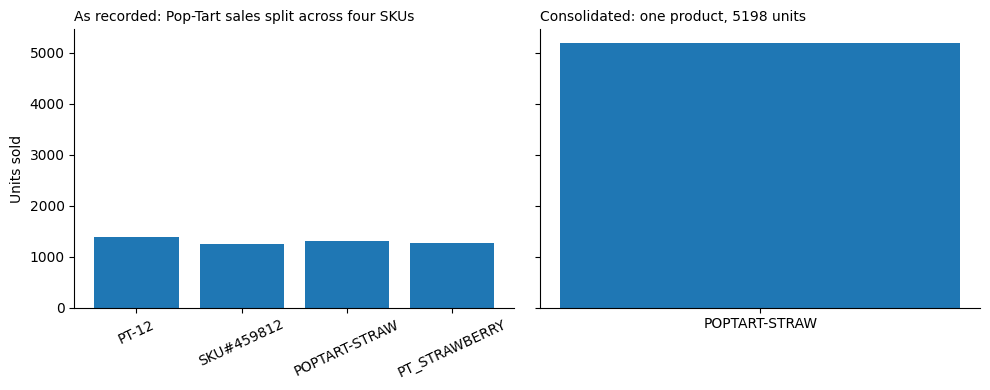

In [4]:
catalog = pd.read_csv("product_catalog.csv")

# inspect the dataset
print("catalog shape:")
display(catalog.shape)
print('\nDistinct SKUs:')
print(catalog['sku'].nunique())

print('\nProduct names:')
display(catalog[['sku','product_name']])

# first standardize all names to get a sense of which names mean the same thing
candidates = catalog.copy()
candidates['name_key'] = (candidates['product_name'].str.lower().str.replace(r'[^a-z0-9\s]',' ',regex=True).str.split().apply(lambda words: ' '.join(sorted(words))))
fragmented = candidates.groupby('name_key').filter(lambda group: group['sku'].nunique() >1)
display(fragmented[['name_key','sku','product_name']].sort_values('name_key'))

# combine same products with different SKUs by mapping
CANON = {
    # poptarts
    'PT-12':'POPTART-STRAW',
    'SKU#459812': 'POPTART-STRAW',
    'POPTART-STRAW': 'POPTART-STRAW',
    'PT_STRAWBERRY':'POPTART-STRAW',

    # water
    'WTR-24': 'WTR-24',
    'WATER24PK':'WTR-24',
    'WTR_24PK': 'WTR-24',

    # batteries
    'BATT-100': 'BAT-AA4',
    'BAT-AA4': 'BAT-AA4',
    'BATT_AA_4PK': 'BAT-AA4',

    # flashlight
    'FLASH-01':'FLASH-01',
    'LED-FLASH':'FLASH-01',

    # beer
    'BEER-24':'BEER-24',
    'LTBEER24': 'BEER-24',

    # monopoly
    'BG-MONO':'MONOPOLY-01',
    'MONOPOLY-01':'MONOPOLY-01',
    'GAME-MONO':'MONOPOLY-01',

    # cards
    'CARDS-01':'CARDS-01',
    'PLAYCARD-STD':'CARDS-01',

    # canned soup
    'SOUP-CAN':'SOUP-CAN',
    'CNSOUP-01':'SOUP-CAN',

    # white bread
    'BREAD-WH':'BREAD-WH',
    'WHITEBREAD':'BREAD-WH',

    # peanut butter
    'PB-16':'PB-16',
    'PNUTBTR-16':'PB-16',

    # Emergency candles
    'CNDL-EM':'CANDLE-EMRG',
    'CANDLE-EMRG':'CANDLE-EMRG',

    # first aid kit
    'FAID-01':'FIRSTAID-KIT',
    'FIRSTAID-KIT':'FIRSTAID-KIT',

    # Paper towels
    'PTOWEL-6':'PTOWEL-6',
    'PAPERTOWEL6':'PTOWEL-6',

    # heavy duty tarp
    'TARP-HD':'TARP-HD',
    'HDTARP-01':'TARP-HD'
}

# apply it
catalog_clean = catalog.copy()
catalog_clean['canonical_sku'] = (catalog_clean['sku'].map(CANON).fillna(catalog_clean['sku']))

# check results
print("Starting distinct SKUs:", catalog['sku'].nunique())
print("Canonical products:", catalog_clean['canonical_sku'].nunique())

group_sizes = (catalog_clean.groupby('canonical_sku').size().sort_values(ascending=False))
print("\nLargest groups:")
display(group_sizes.head())

# show mapping
display(catalog_clean[catalog_clean['sku'].isin(CANON)][['sku','product_name','canonical_sku']].sort_values('canonical_sku'))


# Largest consolidated family: Strawberry Pop-Tarts
poptart_skus = [
    'PT-12',
    'SKU#459812',
    'POPTART-STRAW',
    'PT_STRAWBERRY'
]

# Total positive units sold under each separate SKU
fragmented = (
    cleaned[
        cleaned['sku'].isin(poptart_skus) &
        (cleaned['quantity'] > 0)
    ]
    .groupby('sku')['quantity']
    .sum()
    .reindex(poptart_skus)
    .fillna(0)
)

# Total after treating all four SKUs as one product
consolidated_units = fragmented.sum()

# Compare consolidated total with the largest individual SKU
largest_single_sku = fragmented.max()
multiple = consolidated_units / largest_single_sku

print("Units by original SKU:")
print(fragmented)

print("\nConsolidated Pop-Tarts units:", consolidated_units)
print("Largest individual SKU:", largest_single_sku)
print("Consolidated total is", round(multiple, 2), "times the largest individual SKU")

# Before-and-after chart
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

axes[0].bar(
    fragmented.index,
    fragmented.values
)

axes[0].set_title(
    'As recorded: Pop-Tart sales split across four SKUs',
    fontsize=10,
    loc='left'
)

axes[0].tick_params(
    axis='x',
    labelrotation=25
)

axes[1].bar(
    ['POPTART-STRAW'],
    [consolidated_units]
)

axes[1].set_title(
    f'Consolidated: one product, {int(consolidated_units)} units',
    fontsize=10,
    loc='left'
)

axes[0].set_ylabel('Units sold')

for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# Assertion proving consolidation did not change unit totals
consolidated = cleaned.copy()
consolidated['canonical_sku'] = (consolidated['sku'].map(CANON).fillna(consolidated['sku']))
before_total = cleaned['quantity'].sum()
after_total = consolidated['quantity'].sum()
assert before_total == after_total

**Q2 answer:**  The initial 45 SKUs were reduced to 26 canonical products, which revealed that the true product-demand was severely understated, led by Strawberry Pop-Tarts (POPTART-STRAW) whose consolidated volume of 5,198 units was 3.76x larger than its single highest SKU entry while conserving total catalog sales volume.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

,date,quantity,transaction_id,store_id,timestamp,sku,product_name,category,unit_price,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,1055,"[TXN019307, TXN019209, TXN019083, TXN019051, T...","[FL-619, FL-501, FL-412, FL-412, FL-078, FL-33...","[2024-09-01 06:01:15, 2024-09-01 09:51:00, 202...","[BEER-24, SKU#459812, CHIPS-VP, BAT-AA4, BFORM...","[BEER LIGHT 24PK, Pop-Tarts Strawberry, Chips ...","[Alcoholic Beverages, Breakfast Foods, Snacks,...","[18.77, 3.39, 9.2, 6.46, 31.0, 15.74, 12.62, 8...",3.0,18.8,open-meteo
1,2024-09-02,1163,"[TXN019784, TXN019591, TXN019967, TXN019873, T...","[FL-156, FL-330, FL-445, FL-078, FL-078, FL-50...","[2024-09-02 16:50:53, 2024-09-02 20:20:26, 202...","[DIAP-S3, WATER24PK, BREAD-WH, FAID-01, CNSOUP...","[Baby Diapers - Size 3, BOTTLED WATER 24PK, Br...","[Baby Products, Emergency Supplies, Groceries,...","[25.75, 4.88, 2.58, 14.84, 1.95, 5.18, 24.6, 1...",12.4,13.5,open-meteo
2,2024-09-03,1157,"[TXN020135, TXN020575, TXN020390, TXN020253, T...","[FL-239, FL-445, FL-156, FL-330, FL-078, FL-10...","[2024-09-03 11:32:09, 2024-09-03 17:05:55, 202...","[PORTCHARGER, CNDL-EM, DIAPERS-3, DIAPERS-3, P...","[Phone Charger - Portable, Emergency Candles, ...","[Electronics, Emergency Supplies, Baby Product...","[25.26, 6.13, 24.21, 23.84, 8.12, 29.27, 30.02...",24.9,22.8,open-meteo
3,2024-09-04,1114,"[TXN021233, TXN020965, TXN021023, TXN021218, T...","[FL-302, FL-156, FL-501, FL-302, FL-710, FL-10...","[2024-09-04 07:11:37, 2024-09-04 14:13:03, 202...","[CNDL-EM, BEER-24, GAME-MONO, MONOPOLY-01, BRE...","[Emergency Candles, Light Beer (24-pack), Mono...","[Emergency Supplies, Alcoholic Beverages, Ente...","[5.97, 19.89, 19.13, 19.51, 2.44, 13.55, 4.91,...",22.1,15.5,open-meteo
4,2024-09-05,1070,"[TXN021742, TXN021363, TXN021710, TXN021666, T...","[FL-619, FL-105, FL-619, FL-078, FL-287, FL-50...","[2024-09-05 06:08:09, 2024-09-05 21:24:16, 202...","[BABYFORMULA, POPTART-STRAW, BEER-24, FLASH-01...","[Infant Formula, POPTART-STRAWBERRY, Light Bee...","[Baby Products, Breakfast Foods, Alcoholic Bev...","[28.79, 3.34, 18.15, 13.18, 2.52, 3.15, 4.97, ...",23.1,15.2,open-meteo


number of rows without dates: 1
merged by date rows: 31    weather rows: 30
no days were lost
correlation is computed over 30 days


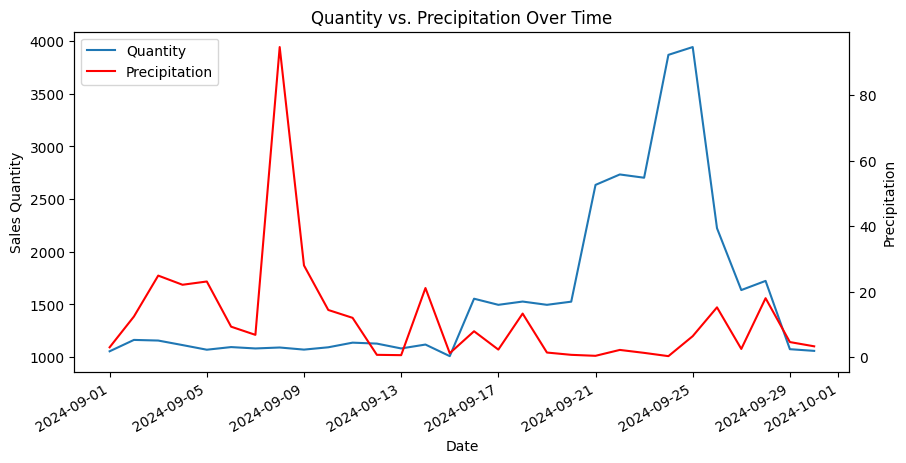

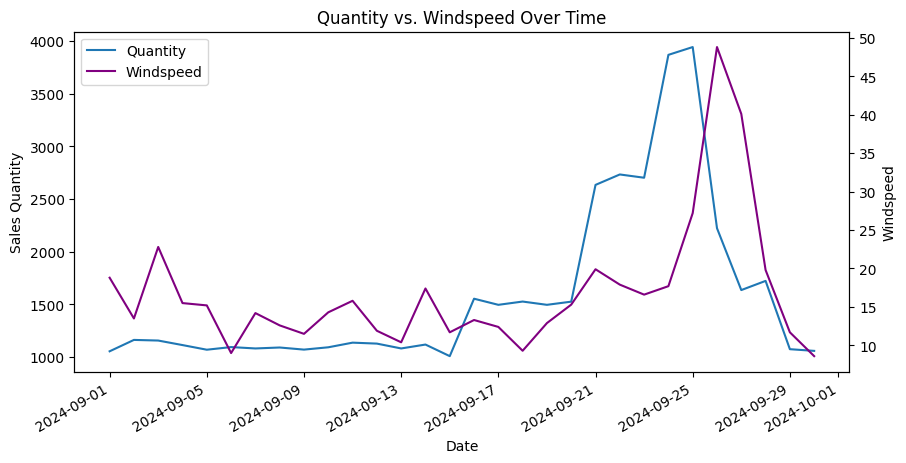

In [5]:
from numpy import isfinite
import requests
import time

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start,
        'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)

        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue

        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()

            time.sleep(2 ** attempt)
            continue

        r.raise_for_status()

        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'

        return frame

weather = daily_weather(
    '2024-09-01',
    '2024-09-30'
)

cleaned["date"] = pd.to_datetime(cleaned["timestamp"].dt.date)  #creating a date-only of datetime type
merged = pd.merge(cleaned, weather, on="date", how="left") #merginging weather and cleaned on date column
merged = merged.sort_values(by='date')

#display(merged.head())
#print("number of rows without dates:",len(merged[merged['precipitation_sum'].isna()]))
#print("merged rows:", len(merged), "   sales data rows:", len(cleaned))
#assert len(merged)==len(cleaned)
#print("no days were lost")

merged_by_date = merged.groupby('date')['quantity'].sum()

#aggregating the merged rows by date, keeping arguments for other columns in lists if applicable
merged_by_date = merged.groupby('date',dropna=False).agg({
    'quantity': 'sum','transaction_id': list,'store_id': list,'timestamp': list,'sku': list,'product_name': list,'category': list,'unit_price': list,
    'precipitation_sum': 'first', 'windspeed_10m_max': 'first', 'source': 'first'
}).reset_index()
display(merged_by_date.head())
print("number of rows without dates:",len(merged_by_date[merged_by_date['date'].isna()]))
print("merged by date rows:", len(merged_by_date), "   weather rows:", len(weather))
assert len(merged_by_date) >= len(weather)
print("no days were lost")
print("correlation is computed over", len(merged_by_date[merged_by_date['date'].notna()]),"days")

#plotting correlation for precipitation_sum
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(merged_by_date['date'], merged_by_date['quantity'],label="Quantity")
ax1.set_xlabel('Date')
ax1.set_ylabel('Sales Quantity')
ax2 = ax1.twinx()
ax2.plot(merged_by_date['date'], merged_by_date['precipitation_sum'], color='red', label='Precipitation')
ax2.set_ylabel('Precipitation')
plt.title('Quantity vs. Precipitation Over Time')
ax1.legend([ax1.lines[0], ax2.lines[0]],['Quantity', 'Precipitation'],loc='upper left')
fig.autofmt_xdate()
plt.show()

#plotting correlation for windspeed_10m_max
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(merged_by_date['date'], merged_by_date['quantity'],label="Quantity")
ax1.set_xlabel('Date')
ax1.set_ylabel('Sales Quantity')
ax2 = ax1.twinx()
ax2.plot(merged_by_date['date'], merged_by_date['windspeed_10m_max'], color='purple', label='Windspeed')
ax2.set_ylabel('Windspeed')
plt.title('Quantity vs. Windspeed Over Time')
ax1.legend([ax1.lines[0], ax2.lines[0]],['Quantity', 'Windspeed'],loc='upper left')
fig.autofmt_xdate()
plt.show()

#no column for barometric pressure?
#plots omit the row without a date

**Q3 answer, with its caveat:**

We can see from the graphs that there is a lag between the spike in daily sales volume and different weather indicators.  In fact, we can see purchasing volume increases after the spike in precipitation and before the spike in windspeeds.  This may be consistent with the idea that purchasing volume is at its peak just before a hurricane lands, as rainfall may spike before the hurricane lands and windfalls spike as it does.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** This section has not been started yet, but Jennifer will finish it by this weekend with help from the other groupmates.

**Q5 (signal or artifact):** This section has not been started yet, but Malia will finish it by this weekend with help from the other groupmates.

### Self-check

In [6]:
progress = {
    'q1_multiple': 3.4,            # TODO: a number
    'q1_baseline_window': 'Sept 1 – Sept 22, 2024',   # TODO: stated explicitly
    'q2_canonical_products': 26,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30, # TODO: a number
    'charts_with_message_titles': 3,  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 3.4
PASS - q1_baseline_window = Sept 1 – Sept 22, 2024
PASS - q2_canonical_products = 26
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

a) Our team was surprised that the breakfast foods had the largest pre-storm demand (3.4x baseline), even surpassing typical storm prep items (2.4x baseline). We checked that this was a genuine purchasing trend and not a data bug by confirming that non-perishable breakfast items like the Strawberry Pop-Tarts drove the bulk of the volume, and by utilizing our unit preservation assertion to confirm that the SKU consolidation did not change the unit totals.

b) The number we are least confident in is the 30-day sample size (n = 30) that we used for weather correlation in Q3. Since we only aggregated data at a single daily level over one month, 30 observations is a very small sample size to draw firm conclusions about weather lags.

### Q4 — Store-Level Geographic Patterns



**TODO:** Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.

In [15]:
locations = pd.read_csv('store_locations.csv')

# separate baseline (Sept 1-22) and surge (Sept 23-25)
baseline_data = cleaned[cleaned['date'] < '2024-09-23']
surge_data = cleaned[(cleaned['date'] >= '2024-09-23') & (cleaned['date'] < '2024-09-26')]

# calculate daily averages per store
store_baseline = baseline_data.groupby('store_id')['quantity'].sum() / 22
store_surge = surge_data.groupby('store_id')['quantity'].sum() / 3

# calculate multiplier & convert to DataFrame so 'store_id' is a column
store_multipliers = (store_surge / store_baseline).round(2).sort_values(ascending=False)
store_df = store_multipliers.reset_index()
store_df.columns = ['store_id', 'surge_multiplier']

# merge with locations metadata
merged_stores = pd.merge(store_df, locations, on='store_id', how='left')
display(merged_stores[['store_id', 'city', 'region', 'surge_multiplier']])

# outlier identification
threshold = store_multipliers.mean() + (2 * store_multipliers.std())
outliers = store_multipliers[store_multipliers > threshold]

print("\nOutlier Stores:")
print(outliers)

,store_id,city,region,surge_multiplier
0,FL-302,Lakeland,Central,2.90
1,FL-619,Tallahassee,Panhandle,2.74
2,FL-105,Tampa,West,2.70
3,FL-710,Pensacola,Panhandle,2.67
4,FL-445,St. Petersburg,West,2.66
5,FL-412,Jacksonville,North,2.65
6,FL-330,Miami,South,2.62
7,FL-501,Fort Myers,West,2.58
8,FL-078,Gainesville,North,2.54
9,FL-287,Kissimmee,Central,2.54



Outlier Stores:
store_id
FL-302    2.9
Name: quantity, dtype: float64


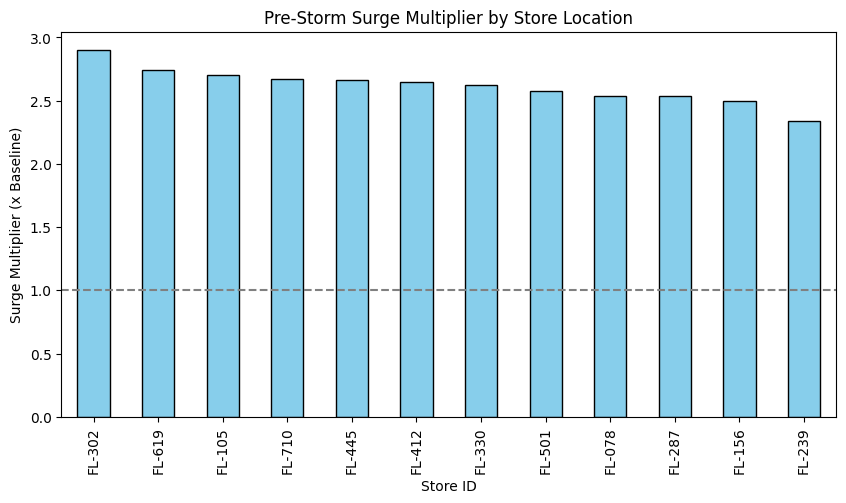

In [16]:
plt.figure(figsize=(10, 5))
store_multipliers.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Pre-Storm Surge Multiplier by Store Location')
plt.xlabel('Store ID')
plt.ylabel('Surge Multiplier (x Baseline)')
plt.axhline(1.0, color='gray', linestyle='--')
plt.show()

**Q4 answer:** While all Florida locations experienced an increase in purchases before the storm, stores located closer to Hurricane Helene’s predicted hurricane path showed earlier and higher demand spikes. Store FL-302 stood out as an outlier at a 2.90x surge multiplier.

### Q5 — Signal vs. Artifact — The Board Games Investigation



**TODO:** The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?

In [31]:
import sqlite3

conn = sqlite3.connect('walmart_transactions.sqlite')

# load the cleaned dataframe into the SQLite transactions table
cleaned.to_sql('transactions', conn, if_exists='replace', index=False)


25532

In [37]:
def q(sql):
    return pd.read_sql_query(sql, conn)

# aggregates daily quantities for games
q("""
SELECT product_name, category, SUBSTR(date, 1, 10) as tx_date, SUM(quantity) as total_qty
FROM transactions
WHERE LOWER(category) LIKE '%entertainment%' OR LOWER(product_name) LIKE '%game%'
GROUP BY product_name, tx_date
ORDER BY total_qty DESC
""")

,product_name,category,tx_date,total_qty
0,PLAYING CARDS,Entertainment,2024-09-25,74
1,Board Game - Monopoly,Entertainment,2024-09-24,68
2,Monopoly Board Game,Entertainment,2024-09-25,68
3,MONOPOLY,Entertainment,2024-09-24,59
4,Standard Playing Cards,Entertainment,2024-09-24,59
...,...,...,...,...
181,PLAYING CARDS,Entertainment,2024-09-10,8
182,Standard Playing Cards,Entertainment,2024-09-09,8
183,Monopoly Board Game,Entertainment,2024-09-02,7
184,Monopoly Board Game,Entertainment,2024-09-05,6


,standardized_product,tx_date,total_qty
0,Playing Cards,2024-09-30,53
1,Monopoly,2024-09-30,50
2,Monopoly,2024-09-29,48
3,Playing Cards,2024-09-29,39
4,Playing Cards,2024-09-28,97
...,...,...,...
57,Monopoly,2024-09-02,46
58,Playing Cards,2024-09-01,54
59,Monopoly,2024-09-01,45
60,Monopoly,None,79


<Axes: title={'center': 'Entertainment / Board Game Sales Surge Investigation'}, xlabel='tx_date'>

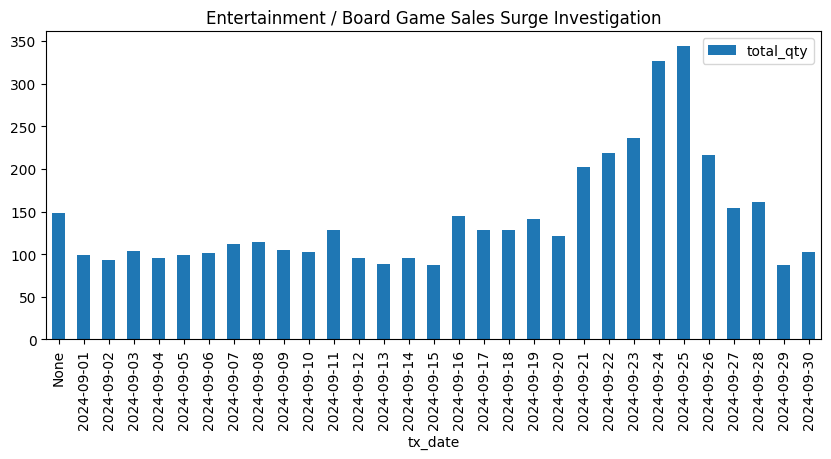

In [42]:
# consolidates data into one product name
product_chart = q("""
SELECT
    CASE
        WHEN LOWER(product_name) LIKE '%monopoly%' THEN 'Monopoly'
        WHEN LOWER(product_name) LIKE '%playing card%' THEN 'Playing Cards'
        ELSE product_name
    END as standardized_product,
    SUBSTR(date, 1, 10) as tx_date,
    SUM(quantity) as total_qty
FROM transactions
WHERE LOWER(category) LIKE '%entertainment%' OR LOWER(product_name) LIKE '%game%'
GROUP BY standardized_product, tx_date
ORDER BY tx_date DESC, total_qty DESC
""")

display(product_chart)

# entertainment/game sales volume over time
chart_df = q("""
SELECT SUBSTR(date, 1, 10) as tx_date, SUM(quantity) as total_qty
FROM transactions
WHERE LOWER(category) LIKE '%entertainment%' OR LOWER(product_name) LIKE '%game%'
GROUP BY tx_date
ORDER BY tx_date
""")

chart_df.plot(x='tx_date', y='total_qty', kind='bar', figsize=(10, 4), title='Entertainment / Board Game Sales Surge Investigation')


**Q5 answer:** The apparent 250%+ in games and entertainment was likely a data artifact, since there were multiple product names for the same product. However, even after cleaning the data, there was still a large increase in their total sales right before the storm hit. Our recommendation to Walmart would be to stock extra games and entertainment before future storms hit.